In [1]:
print("Hello")

Hello


In [2]:
import os
import pandas as pd

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/bhanupratapbiswas/customer-behavior-analysis/ecommerce_customer_data_large.csv
/kaggle/input/datasets/bhanupratapbiswas/customer-behavior-analysis/ecommerce_customer_data_custom_ratios.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "/kaggle/input/datasets/bhanupratapbiswas/customer-behavior-analysis/ecommerce_customer_data_large.csv"
)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Number of rows and columns: (250000, 13)


,Customer ID,Purchase Date,Product Category,Product Price,Quantity,Total Purchase Amount,Payment Method,Customer Age,Returns,Customer Name,Age,Gender,Churn
0,44605,2023-05-03 21:30:02,Home,177,1,2427,PayPal,31,1.0,John Rivera,31,Female,0
1,44605,2021-05-16 13:57:44,Electronics,174,3,2448,PayPal,31,1.0,John Rivera,31,Female,0
2,44605,2020-07-13 06:16:57,Books,413,1,2345,Credit Card,31,1.0,John Rivera,31,Female,0
3,44605,2023-01-17 13:14:36,Electronics,396,3,937,Cash,31,0.0,John Rivera,31,Female,0
4,44605,2021-05-01 11:29:27,Books,259,4,2598,PayPal,31,1.0,John Rivera,31,Female,0


In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Column names:
['Customer ID', 'Purchase Date', 'Product Category', 'Product Price', 'Quantity', 'Total Purchase Amount', 'Payment Method', 'Customer Age', 'Returns', 'Customer Name', 'Age', 'Gender', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 13 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Customer ID            250000 non-null  int64  
 1   Purchase Date          250000 non-null  object 
 2   Product Category       250000 non-null  object 
 3   Product Price          250000 non-null  int64  
 4   Quantity               250000 non-null  int64  
 5   Total Purchase Amount  250000 non-null  int64  
 6   Payment Method         250000 non-null  object 
 7   Customer Age           250000 non-null  int64  
 8   Returns                202618 non-null  float64
 9   Customer Name          250000 non-null  object 
 10  Age              

In [5]:
# Make a copy of the original dataset
df_clean = df.copy()

# Remove duplicate rows
print("Duplicate rows:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()

# Convert purchase date if available
if "Purchase Date" in df_clean.columns:
    df_clean["Purchase Date"] = pd.to_datetime(
        df_clean["Purchase Date"], errors="coerce"
    )

print("Cleaned dataset shape:", df_clean.shape)
display(df_clean.head())

Duplicate rows: 0
Cleaned dataset shape: (250000, 13)


,Customer ID,Purchase Date,Product Category,Product Price,Quantity,Total Purchase Amount,Payment Method,Customer Age,Returns,Customer Name,Age,Gender,Churn
0,44605,2023-05-03 21:30:02,Home,177,1,2427,PayPal,31,1.0,John Rivera,31,Female,0
1,44605,2021-05-16 13:57:44,Electronics,174,3,2448,PayPal,31,1.0,John Rivera,31,Female,0
2,44605,2020-07-13 06:16:57,Books,413,1,2345,Credit Card,31,1.0,John Rivera,31,Female,0
3,44605,2023-01-17 13:14:36,Electronics,396,3,937,Cash,31,0.0,John Rivera,31,Female,0
4,44605,2021-05-01 11:29:27,Books,259,4,2598,PayPal,31,1.0,John Rivera,31,Female,0


In [6]:
print(df_clean.columns.tolist())
display(df_clean.head(10))

['Customer ID', 'Purchase Date', 'Product Category', 'Product Price', 'Quantity', 'Total Purchase Amount', 'Payment Method', 'Customer Age', 'Returns', 'Customer Name', 'Age', 'Gender', 'Churn']


,Customer ID,Purchase Date,Product Category,Product Price,Quantity,Total Purchase Amount,Payment Method,Customer Age,Returns,Customer Name,Age,Gender,Churn
0,44605,2023-05-03 21:30:02,Home,177,1,2427,PayPal,31,1.0,John Rivera,31,Female,0
1,44605,2021-05-16 13:57:44,Electronics,174,3,2448,PayPal,31,1.0,John Rivera,31,Female,0
2,44605,2020-07-13 06:16:57,Books,413,1,2345,Credit Card,31,1.0,John Rivera,31,Female,0
3,44605,2023-01-17 13:14:36,Electronics,396,3,937,Cash,31,0.0,John Rivera,31,Female,0
4,44605,2021-05-01 11:29:27,Books,259,4,2598,PayPal,31,1.0,John Rivera,31,Female,0
5,13738,2022-08-25 06:48:33,Home,191,3,3722,Credit Card,27,1.0,Lauren Johnson,27,Female,0
6,13738,2023-07-25 05:17:24,Electronics,205,1,2773,Credit Card,27,NaN,Lauren Johnson,27,Female,0
7,13738,2023-02-05 19:31:48,Books,370,5,1486,Cash,27,1.0,Lauren Johnson,27,Female,0
8,13738,2021-12-21 03:29:05,Home,12,2,2175,Cash,27,NaN,Lauren Johnson,27,Female,0
9,13738,2023-02-09 00:53:14,Electronics,40,4,4327,Cash,27,0.0,Lauren Johnson,27,Female,0


In [7]:
# Basic customer and transaction analysis

print("Total records:", len(df_clean))

print("Dataset columns:")
print(df_clean.columns.tolist())

print("\nDataset summary:")
display(df_clean.describe(include="all").T)

print("\nMissing values:")
display(df_clean.isnull().sum().to_frame("Missing Values"))

Total records: 250000
Dataset columns:
['Customer ID', 'Purchase Date', 'Product Category', 'Product Price', 'Quantity', 'Total Purchase Amount', 'Payment Method', 'Customer Age', 'Returns', 'Customer Name', 'Age', 'Gender', 'Churn']

Dataset summary:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Customer ID,250000.0,NaN,NaN,NaN,25017.632092,1.0,12590.0,25011.0,37441.25,50000.0,14412.515718
Purchase Date,250000,NaN,NaN,NaN,2021-11-06 19:26:22.286192384,2020-01-01 00:07:26,2020-12-03 08:10:12,2021-11-06 07:39:08.500000,2022-10-11 01:21:56.249999872,2023-09-13 18:42:49,NaN
Product Category,250000,4,Electronics,62630,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Price,250000.0,NaN,NaN,NaN,254.742724,10.0,132.0,255.0,377.0,500.0,141.738104
Quantity,250000.0,NaN,NaN,NaN,3.004936,1.0,2.0,3.0,4.0,5.0,1.414737
Total Purchase Amount,250000.0,NaN,NaN,NaN,2725.385196,100.0,1476.0,2725.0,3975.0,5350.0,1442.576095
Payment Method,250000,3,Credit Card,83547,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Age,250000.0,NaN,NaN,NaN,43.798276,18.0,30.0,44.0,57.0,70.0,15.364915
Returns,202618.0,NaN,NaN,NaN,0.500824,0.0,0.0,1.0,1.0,1.0,0.500001
Customer Name,250000,39878,Michael Johnson,119,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


,Missing Values
Customer ID,0
Purchase Date,0
Product Category,0
Product Price,0
Quantity,0
Total Purchase Amount,0
Payment Method,0
Customer Age,0
Returns,47382
Customer Name,0


In [8]:
for col in df_clean.columns:
    print(col)

Customer ID
Purchase Date
Product Category
Product Price
Quantity
Total Purchase Amount
Payment Method
Customer Age
Returns
Customer Name
Age
Gender
Churn


In [9]:

# TASK 1: DATA CLEANING AND FEATURE ENGINEERING

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create a separate working copy
df_clean = df_clean.copy()

# Convert purchase date to datetime
df_clean["Purchase Date"] = pd.to_datetime(
    df_clean["Purchase Date"], errors="coerce"
)

# Remove duplicate records
df_clean = df_clean.drop_duplicates().copy()

# Convert numeric columns
numeric_cols = [
    "Customer ID",
    "Product Price",
    "Quantity",
    "Total Purchase Amount",
    "Customer Age",
    "Churn"
]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

# Remove rows missing essential analysis fields
df_clean = df_clean.dropna(
    subset=[
        "Customer ID",
        "Purchase Date",
        "Total Purchase Amount"
    ]
).copy()

# Create useful features
df_clean["Purchase Month"] = (
    df_clean["Purchase Date"].dt.to_period("M").astype(str)
)

df_clean["Purchase Day"] = (
    df_clean["Purchase Date"].dt.day_name()
)

df_clean["Age Group"] = pd.cut(
    df_clean["Customer Age"],
    bins=[17, 25, 35, 50, 70],
    labels=["18-25", "26-35", "36-50", "51-70"]
)

print("Data cleaning and feature engineering completed!")
print("Final dataset shape:", df_clean.shape)
print("\nMissing values:")
print(df_clean.isnull().sum())


Data cleaning and feature engineering completed!
Final dataset shape: (250000, 16)

Missing values:
Customer ID                  0
Purchase Date                0
Product Category             0
Product Price                0
Quantity                     0
Total Purchase Amount        0
Payment Method               0
Customer Age                 0
Returns                  47382
Customer Name                0
Age                          0
Gender                       0
Churn                        0
Purchase Month               0
Purchase Day                 0
Age Group                    0
dtype: int64


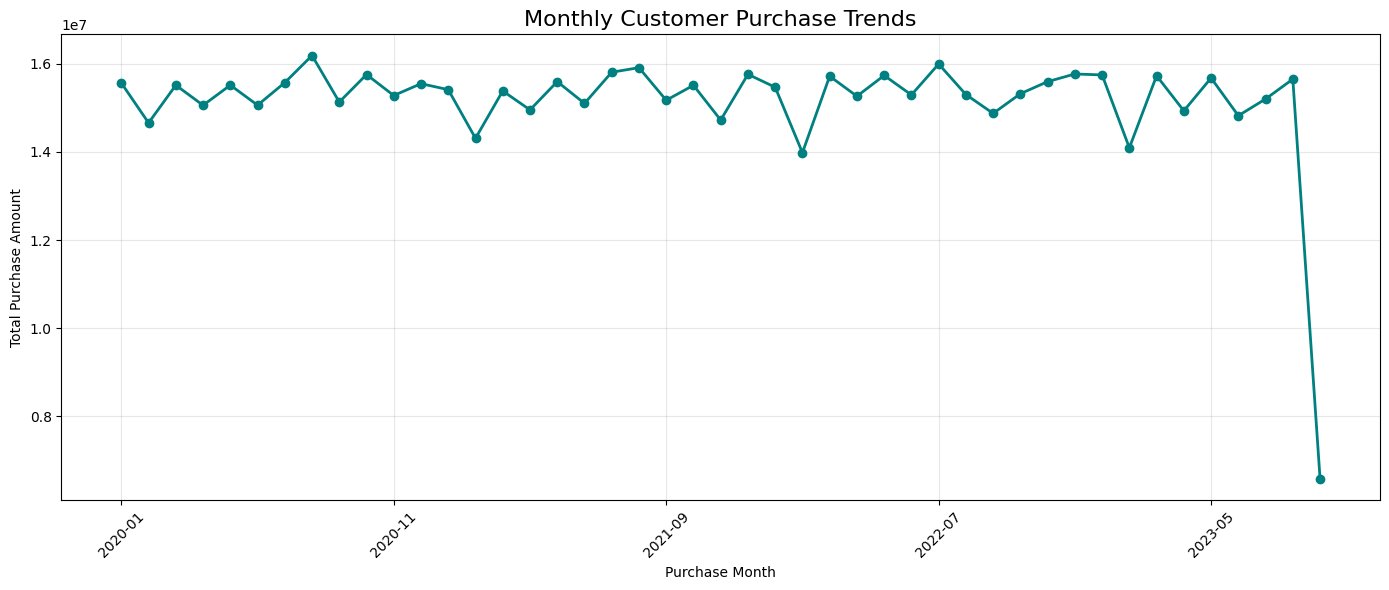

Top 5 months by purchase amount:


,Total Purchase Amount
Purchase Month,
2020-08,16190648
2022-07,15997688
2021-08,15914473
2021-07,15811231
2022-12,15771054


In [10]:

# MONTHLY PURCHASE ANALYSIS

monthly_sales = (
    df_clean.groupby("Purchase Month")["Total Purchase Amount"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(14, 6))
monthly_sales.plot(
    marker="o",
    color="teal",
    linewidth=2
)

plt.title("Monthly Customer Purchase Trends", fontsize=16)
plt.xlabel("Purchase Month")
plt.ylabel("Total Purchase Amount")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Top 5 months by purchase amount:")
display(
    monthly_sales.sort_values(ascending=False)
    .head(5)
    .to_frame("Total Purchase Amount")
)


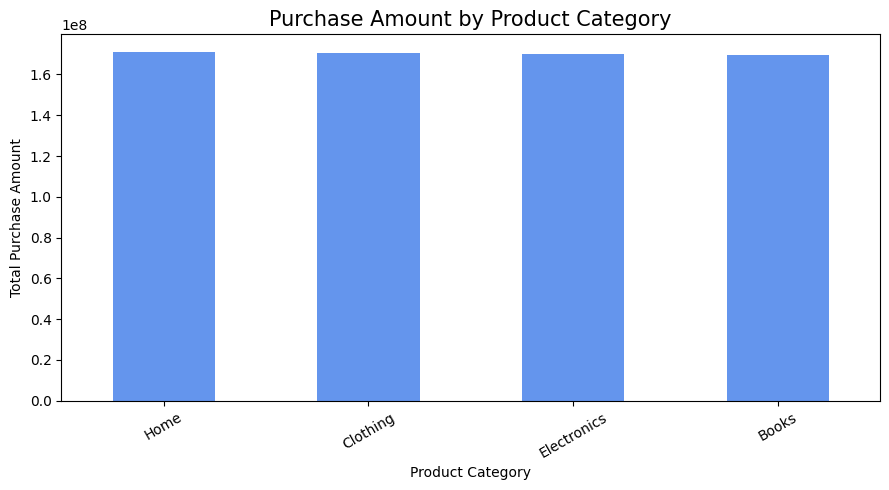

,Total Purchase Amount
Product Category,
Home,171138916
Clothing,170716122
Electronics,170146025
Books,169345236


In [11]:

# SALES BY PRODUCT CATEGORY

category_sales = (
    df_clean.groupby("Product Category")["Total Purchase Amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
category_sales.plot(
    kind="bar",
    color="cornflowerblue"
)

plt.title("Purchase Amount by Product Category", fontsize=15)
plt.xlabel("Product Category")
plt.ylabel("Total Purchase Amount")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(category_sales.to_frame("Total Purchase Amount"))


Churn counts:


,Number of Records
Churn,
0,199870
1,50130


Record-level churn rate: 20.05%


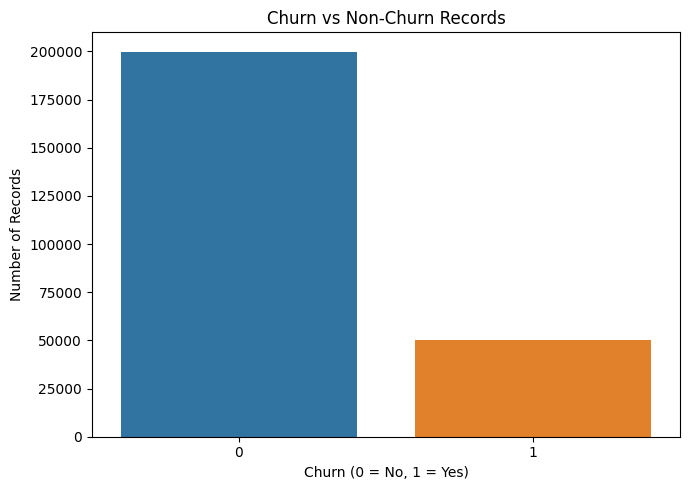

In [12]:

# CUSTOMER CHURN ANALYSIS

churn_counts = df_clean["Churn"].value_counts().sort_index()

print("Churn counts:")
display(churn_counts.to_frame("Number of Records"))

churn_rate = df_clean["Churn"].mean() * 100
print(f"Record-level churn rate: {churn_rate:.2f}%")

plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x="Churn", hue="Churn", legend=False)

plt.title("Churn vs Non-Churn Records")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


In [14]:

# RFM CUSTOMER SEGMENTATION

# Use one row per customer for RFM analysis
reference_date = (
    df_clean["Purchase Date"].max()
    + pd.Timedelta(days=1)
)

rfm = df_clean.groupby("Customer ID").agg(
    Last_Purchase=("Purchase Date", "max"),
    Frequency=("Purchase Date", "count"),
    Monetary=("Total Purchase Amount", "sum"),
    Churn=("Churn", "max")
)

# Recency = days since last recorded purchase
rfm["Recency"] = (
    reference_date - rfm["Last_Purchase"]
).dt.days

# Create RFM scores
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Assign customer segments
def assign_segment(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4:
        return "Loyal / Active"
    elif row["R_Score"] <= 2 and row["M_Score"] >= 4:
        return "At-Risk High-Value"
    elif row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "Recent / New"
    elif row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "Inactive / At-Risk"
    else:
        return "Regular Customers"

rfm["Segment"] = rfm.apply(assign_segment, axis=1)

# Summarize customer segments
segment_summary = rfm.groupby("Segment").agg(
    Customers=("Customer ID", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Spending=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2)

display(segment_summary)


KeyError: "Column(s) ['Customer ID'] do not exist"

In [15]:

# FIXED RFM CUSTOMER SEGMENT SUMMARY

segment_summary = rfm.groupby("Segment").agg(
    Customers=("Recency", "size"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Spending=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2)

display(segment_summary)


,Customers,Average_Recency,Average_Frequency,Average_Spending,Total_Revenue
Segment,,,,,
At-Risk High-Value,5199,401.64,6.41,19449.04,101115554
Inactive / At-Risk,10931,566.94,2.76,7400.32,80892846
Loyal / Active,10592,61.08,7.37,20083.87,212728342
Recent / New,5373,66.78,3.25,8853.82,47571550
Regular Customers,17566,212.73,5.18,13607.99,239038007


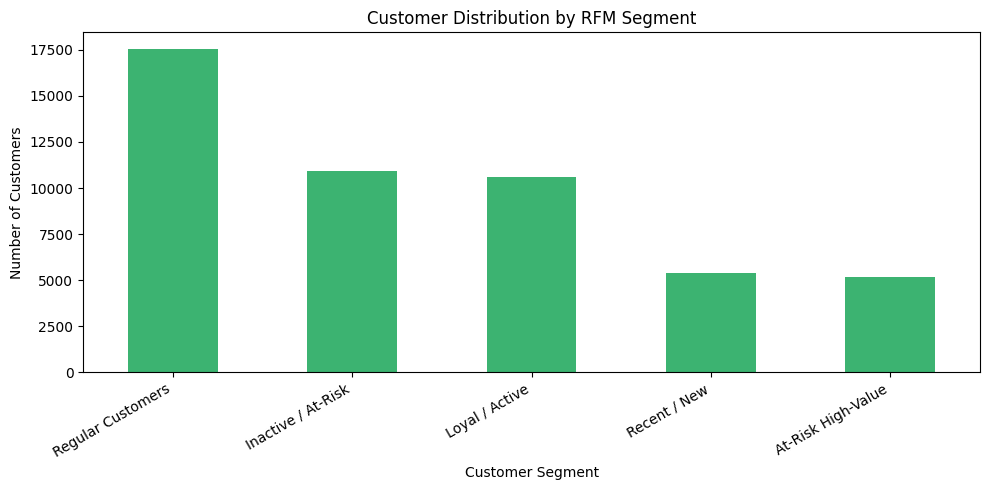

,Number of Customers
Segment,
Regular Customers,17566
Inactive / At-Risk,10931
Loyal / Active,10592
Recent / New,5373
At-Risk High-Value,5199


In [16]:

import matplotlib.pyplot as plt

segment_counts = rfm["Segment"].value_counts()

plt.figure(figsize=(10, 5))
segment_counts.plot(kind="bar", color="mediumseagreen")

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

display(segment_counts.to_frame("Number of Customers"))


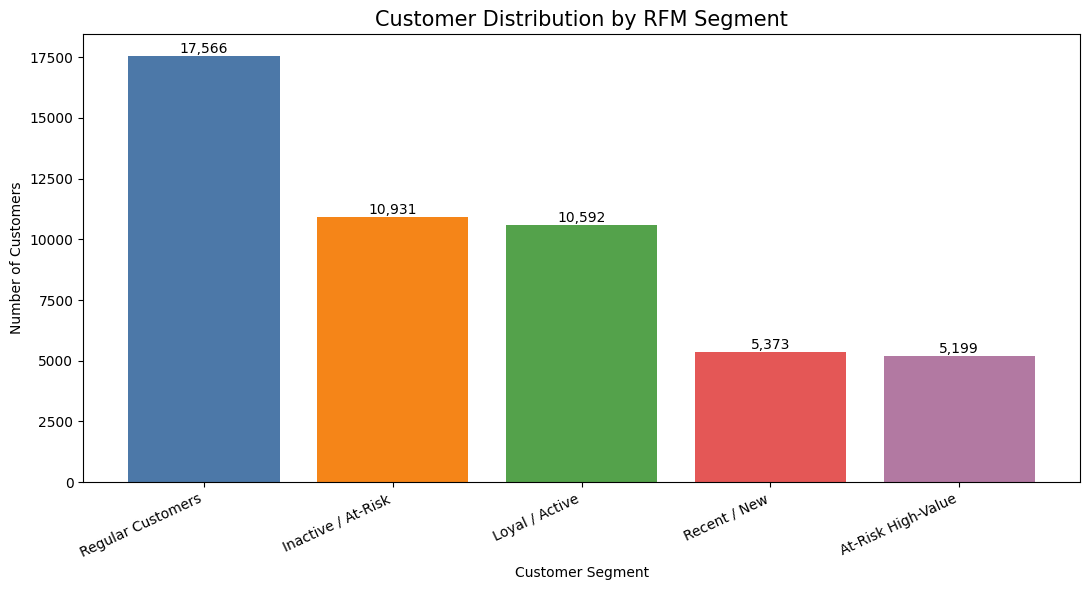

In [17]:

# RFM CUSTOMER SEGMENT VISUALIZATION

import matplotlib.pyplot as plt

segment_counts = rfm["Segment"].value_counts()

plt.figure(figsize=(11, 6))
bars = plt.bar(
    segment_counts.index,
    segment_counts.values,
    color=["#4C78A8", "#F58518", "#54A24B", "#E45756", "#B279A2"]
)

plt.title("Customer Distribution by RFM Segment", fontsize=15)
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25, ha="right")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("customer_segments.png", dpi=300, bbox_inches="tight")
plt.show()


In [18]:

# SAVE PROJECT OUTPUTS

rfm.to_csv("customer_rfm_segments.csv")
segment_summary.to_csv("customer_segment_summary.csv")
monthly_sales.to_csv("monthly_purchase_trends.csv")
category_sales.to_csv("category_sales.csv")

print("All analysis files saved successfully!")


All analysis files saved successfully!
